In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
from sklearn.utils.class_weight import compute_sample_weight

In [ ]:
noaa = pd.read_csv('madinah_makkah.txt', sep=r'\s+', skiprows=21)
noaa['date'] = pd.to_datetime(noaa[['YYYY','MM','DD']].astype(str).agg('-'.join, axis=1))
noaa = noaa.rename(columns={'SSTA@90th_HS': 'SST_anomaly', '90th_HS>0': 'HotSpot', 'DHW_from_90th_HS>1': 'DHW'})
noaa_clean = noaa[['date', 'SST_MIN', 'SST_MAX', 'SST_anomaly', 'HotSpot', 'DHW']]
print(len(noaa_clean), noaa_clean['date'].min().date(), noaa_clean['date'].max().date())

15214 1985-01-01 2026-08-27


In [ ]:
iod = pd.read_csv('dmi_had_long.csv')
iod.columns = ['date', 'IOD']
iod['date'] = pd.to_datetime(iod['date'])
iod_clean = iod[iod['IOD'] != -9999].copy()
print(len(iod_clean), iod_clean['date'].min().date(), iod_clean['date'].max().date())

1877 1870-01-01 2026-05-01


In [ ]:
SOLAR_FILENAME = 'b3ca1603937c947bf73a784eacefbce9.csv'
solar = pd.read_csv(SOLAR_FILENAME, sep=';', skiprows=42)
solar.columns = [c.replace('# ', '').strip() for c in solar.columns]
solar['date'] = pd.to_datetime(solar['Observation period'].str.split('/').str[0])
solar['cloud_ratio'] = solar['GHI'] / solar['Clear sky GHI']
solar_clean = solar[['date', 'cloud_ratio']].dropna()
print(len(solar_clean), solar_clean['date'].min().date(), solar_clean['date'].max().date())

6902 2004-02-01 2022-12-31


In [ ]:
merged = pd.merge(noaa_clean, solar_clean, on='date', how='inner')
merged['year_month'] = merged['date'].dt.to_period('M')
iod_clean['year_month'] = iod_clean['date'].dt.to_period('M')
final = pd.merge(merged, iod_clean[['year_month', 'IOD']], on='year_month', how='left').drop(columns=['year_month'])
print(len(final))
print(final.isnull().sum())

6902
date           0
SST_MIN        0
SST_MAX        0
SST_anomaly    0
HotSpot        0
DHW            0
cloud_ratio    0
IOD            0
dtype: int64


In [ ]:
final = final.sort_values('date').reset_index(drop=True)
final['SST_mean'] = (final['SST_MIN'] + final['SST_MAX']) / 2
final['histSSTSD'] = final['SST_mean'].rolling(window=30, min_periods=30).std()
final_ready = final.dropna(subset=['histSSTSD']).reset_index(drop=True)
final_ready.to_csv('final_dataset_ready.csv', index=False)
print(len(final_ready), final_ready['date'].min().date(), final_ready['date'].max().date())

6873 2004-03-01 2022-12-31


In [ ]:
final_ready['year'] = final_ready['date'].dt.year
final_ready['month'] = final_ready['date'].dt.month
monthly_avg_dhw = final_ready.groupby('month')['DHW'].agg(['mean', 'max'])
print(monthly_avg_dhw)

           mean      max
month                   
1      0.062497   2.1314
2      0.000000   0.0000
3      0.000000   0.0000
4      0.000000   0.0000
5      0.000000   0.0000
6      0.114011   1.6629
7      0.266750   1.6629
8      1.687460   7.3057
9      3.461813  13.2286
10     4.401903  17.4157
11     2.723756  16.1414
12     1.033572   9.9186


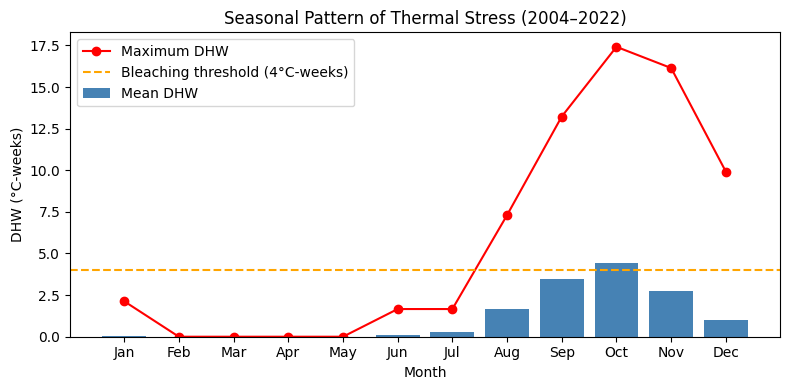

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
ax.bar(months, monthly_avg_dhw['mean'], color='steelblue', label='Mean DHW')
ax.plot(months, monthly_avg_dhw['max'], 'ro-', label='Maximum DHW')
ax.axhline(y=4, color='orange', linestyle='--', label='Bleaching threshold (4°C-weeks)')
ax.set_xlabel('Month')
ax.set_ylabel('DHW (°C-weeks)')
ax.set_title('Seasonal Pattern of Thermal Stress (2004–2022)')
ax.legend()
plt.tight_layout()
plt.savefig('figure2_seasonal_pattern.png', dpi=300)
plt.show()

In [ ]:
SEASON_MONTHS = [8, 9, 10, 11, 12]

def compute_target_for_year(year_data):
    year_data = year_data.sort_values('date').reset_index(drop=True)
    dhw_values = year_data['DHW'].values
    n = len(year_data)
    targets = []
    for i in range(n):
        found = False
        for weeks_ahead in range(0, 7):
            idx = i + weeks_ahead * 7
            if idx < n and dhw_values[idx] >= 4.0:
                targets.append(str(weeks_ahead))
                found = True
                break
        if not found:
            targets.append('no-onset')
    return targets

all_targets = []
for year in sorted(final_ready['year'].unique()):
    mask = (final_ready['year'] == year) & (final_ready['month'].isin(SEASON_MONTHS))
    yd = final_ready[mask]
    if len(yd) > 0:
        td = yd[['date']].copy()
        td['target'] = compute_target_for_year(yd)
        all_targets.append(td)

targets_df = pd.concat(all_targets, ignore_index=True)
print(targets_df['target'].value_counts())

target
no-onset    1970
0            756
1             56
2             53
3             38
4             14
5             10
6              7
Name: count, dtype: int64


In [ ]:
model_data = pd.merge(final_ready, targets_df, on='date', how='inner')
model_data.to_csv('model_data_with_target.csv', index=False)
print(len(model_data))

2904


In [ ]:
TEST_YEARS = [2019, 2020, 2021, 2022]
train_data = model_data[~model_data['year'].isin(TEST_YEARS)].copy()
test_data = model_data[model_data['year'].isin(TEST_YEARS)].copy()
train_data.to_csv('train_data.csv', index=False)
test_data.to_csv('test_data.csv', index=False)
print(len(train_data), len(test_data))

2292 612


In [ ]:
def simplify_target(t):
    if t == 'no-onset':
        return 0
    weeks = int(t)
    return 1 if weeks <= 2 else 2

train_data['target_encoded'] = train_data['target'].apply(simplify_target)
test_data['target_encoded'] = test_data['target'].apply(simplify_target)
print(train_data['target_encoded'].value_counts())
print(test_data['target_encoded'].value_counts())

target_encoded
0    1719
1     516
2      57
Name: count, dtype: int64
target_encoded
1    349
0    251
2     12
Name: count, dtype: int64


In [ ]:
FEATURES_BASIC = ['DHW', 'HotSpot', 'SST_anomaly']
X_train = train_data[FEATURES_BASIC]
y_train = train_data['target_encoded']
X_test = test_data[FEATURES_BASIC]
y_test = test_data['target_encoded']

sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

model_basic = XGBClassifier(n_estimators=100, max_depth=4, random_state=42, eval_metric='mlogloss')
model_basic.fit(X_train, y_train, sample_weight=sample_weights)

y_pred_basic = model_basic.predict(X_test)
print(classification_report(y_test, y_pred_basic, zero_division=0))

              precision    recall  f1-score   support

           0       0.93      0.94      0.93       251
           1       0.99      0.96      0.97       349
           2       0.10      0.17      0.12        12

    accuracy                           0.93       612
   macro avg       0.67      0.69      0.68       612
weighted avg       0.94      0.93      0.94       612



In [ ]:
FEATURES_EXTENDED = ['DHW', 'HotSpot', 'SST_anomaly', 'histSSTSD', 'IOD', 'cloud_ratio']
X_train_ext = train_data[FEATURES_EXTENDED]
X_test_ext = test_data[FEATURES_EXTENDED]

model_extended = XGBClassifier(n_estimators=100, max_depth=4, random_state=42, eval_metric='mlogloss')
model_extended.fit(X_train_ext, y_train, sample_weight=sample_weights)

y_pred_ext = model_extended.predict(X_test_ext)
print(classification_report(y_test, y_pred_ext, zero_division=0))

              precision    recall  f1-score   support

           0       0.89      0.90      0.90       251
           1       1.00      0.95      0.98       349
           2       0.00      0.00      0.00        12

    accuracy                           0.91       612
   macro avg       0.63      0.62      0.62       612
weighted avg       0.93      0.91      0.92       612



In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
logreg.fit(X_train_s, y_train)
y_pred_lr = logreg.predict(X_test_s)

print('Logistic Regression')
print(classification_report(y_test, y_pred_lr, zero_division=0))

Logistic Regression
              precision    recall  f1-score   support

           0       0.99      0.80      0.88       251
           1       0.97      0.94      0.95       349
           2       0.14      0.83      0.24        12

    accuracy                           0.88       612
   macro avg       0.70      0.86      0.69       612
weighted avg       0.96      0.88      0.91       612



In [ ]:
train_data['doy'] = pd.to_datetime(train_data['date']).dt.dayofyear
test_data['doy'] = pd.to_datetime(test_data['date']).dt.dayofyear

doy_mode = train_data.groupby('doy')['target_encoded'].agg(lambda s: s.mode()[0])
overall_mode = train_data['target_encoded'].mode()[0]

y_pred_freq = test_data['doy'].map(doy_mode).fillna(overall_mode).astype(int)

print('Frequency Model')
print(classification_report(y_test, y_pred_freq, zero_division=0))

Frequency Model
              precision    recall  f1-score   support

           0       0.41      1.00      0.58       251
           1       0.00      0.00      0.00       349
           2       0.00      0.00      0.00        12

    accuracy                           0.41       612
   macro avg       0.14      0.33      0.19       612
weighted avg       0.17      0.41      0.24       612



In [ ]:
rows = []
for name, pred in [('XGBoost (baseline)', y_pred_basic),
                   ('XGBoost (extended)', y_pred_ext),
                   ('Logistic Regression', y_pred_lr),
                   ('Frequency model', y_pred_freq)]:
    f1 = f1_score(y_test, pred, average=None, zero_division=0)
    rows.append({'Model': name, 'No risk': round(f1[0],3),
                 'Urgent': round(f1[1],3), 'Distant': round(f1[2],3),
                 'Accuracy': round((pred == y_test).mean(),3)})

print(pd.DataFrame(rows).to_string(index=False))

              Model  No risk  Urgent  Distant  Accuracy
 XGBoost (baseline)    0.931   0.972    0.125     0.933
 XGBoost (extended)    0.895   0.975    0.000     0.913
Logistic Regression    0.883   0.953    0.241     0.879
    Frequency model    0.582   0.000    0.000     0.410


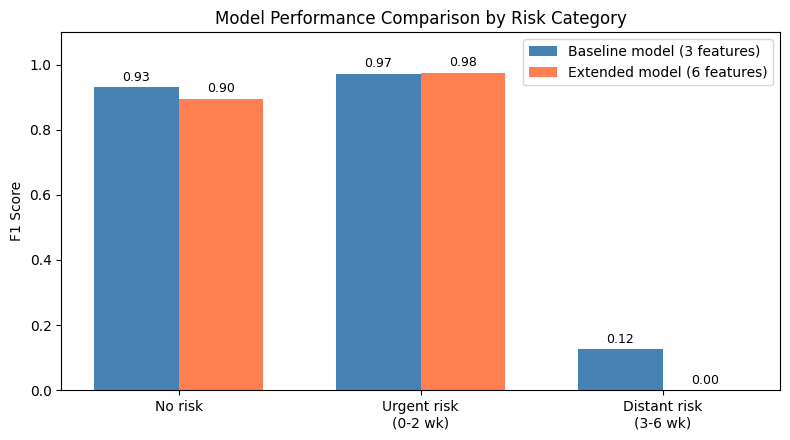

In [ ]:
from sklearn.metrics import f1_score

f1_basic = f1_score(y_test, y_pred_basic, average=None, zero_division=0)
f1_ext = f1_score(y_test, y_pred_ext, average=None, zero_division=0)

labels = ['No risk', 'Urgent risk\n(0-2 wk)', 'Distant risk\n(3-6 wk)']
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - width/2, f1_basic, width, label='Baseline model (3 features)', color='steelblue')
ax.bar(x + width/2, f1_ext, width, label='Extended model (6 features)', color='coral')

for i, (b, e) in enumerate(zip(f1_basic, f1_ext)):
    ax.text(i - width/2, b + 0.02, f'{b:.2f}', ha='center', fontsize=9)
    ax.text(i + width/2, e + 0.02, f'{e:.2f}', ha='center', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('F1 Score')
ax.set_ylim(0, 1.1)
ax.set_title('Model Performance Comparison by Risk Category')
ax.legend()
plt.tight_layout()
plt.savefig('figure3_model_comparison.png', dpi=300)
plt.show()

In [ ]:
!pip install shap -q
import shap

In [ ]:
explainer = shap.TreeExplainer(model_basic)
shap_values = explainer.shap_values(X_test)

class_labels = ['No risk', 'Urgent risk (0-2 wk)', 'Distant risk (3-6 wk)']
importance_matrix = []

for class_idx, class_name in enumerate(class_labels):
    class_shap = shap_values[:, :, class_idx]
    importance = np.abs(class_shap).mean(axis=0)
    importance_matrix.append(importance)
    print(class_name)
    for feat, imp in sorted(zip(FEATURES_BASIC, importance), key=lambda x: -x[1]):
        print(f'  {feat}: {imp:.4f}')
    print()

importance_matrix = np.array(importance_matrix)

No risk
  DHW: 2.7883
  HotSpot: 1.3703
  SST_anomaly: 0.5936

Urgent risk (0-2 wk)
  DHW: 4.3488
  HotSpot: 0.8270
  SST_anomaly: 0.5261

Distant risk (3-6 wk)
  HotSpot: 2.0565
  DHW: 1.7155
  SST_anomaly: 0.9161



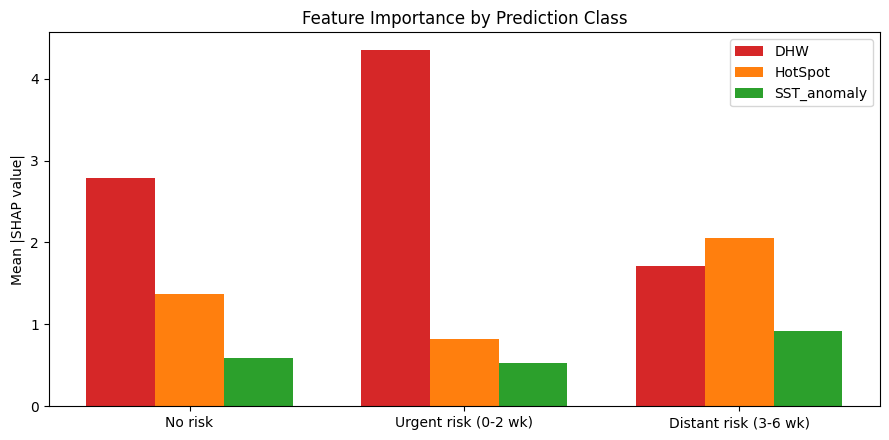

In [ ]:
x = np.arange(len(class_labels))
width = 0.25
colors = ['#d62728', '#ff7f0e', '#2ca02c']

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, feat in enumerate(FEATURES_BASIC):
    ax.bar(x + (i - 1) * width, importance_matrix[:, i], width, label=feat, color=colors[i])

ax.set_xticks(x)
ax.set_xticklabels(class_labels)
ax.set_ylabel('Mean |SHAP value|')
ax.set_title('Feature Importance by Prediction Class')
ax.legend()
plt.tight_layout()
plt.savefig('figure4_shap_importance.png', dpi=300)
plt.show()

In [ ]:
data_2020 = test_data[test_data['year'] == 2020].copy().sort_values('date').reset_index(drop=True)
X_2020 = data_2020[FEATURES_BASIC]
probs_2020 = model_basic.predict_proba(X_2020)
data_2020['prediction'] = model_basic.predict(X_2020)
data_2020['prob_urgent_risk'] = probs_2020[:, 1]

important_period = data_2020[(data_2020['date'] >= '2020-08-01') & (data_2020['date'] <= '2020-10-20')]
print(important_period[['date', 'DHW', 'prediction', 'prob_urgent_risk']].to_string(index=False))

      date     DHW  prediction  prob_urgent_risk
2020-08-01  0.0000           0          0.000469
2020-08-02  0.0000           0          0.000456
2020-08-03  0.1557           0          0.000605
2020-08-04  0.3414           2          0.001944
2020-08-05  0.5386           0          0.000086
2020-08-06  0.7071           2          0.000208
2020-08-07  0.8643           0          0.007761
2020-08-08  1.0771           2          0.000215
2020-08-09  1.2743           2          0.000621
2020-08-10  1.5071           0          0.003108
2020-08-11  1.7957           1          0.953024
2020-08-12  2.0343           1          0.871112
2020-08-13  2.2629           1          0.927300
2020-08-14  2.4743           1          0.914717
2020-08-15  2.6986           1          0.996297
2020-08-16  2.9343           1          0.996930
2020-08-17  3.1786           1          0.998564
2020-08-18  3.4200           1          0.999441
2020-08-19  3.6514           1          0.999441
2020-08-20  3.8771  

In [ ]:
noaa_full = pd.read_csv('madinah_makkah.txt', sep=r'\s+', skiprows=21)
noaa_full['date'] = pd.to_datetime(noaa_full[['YYYY','MM','DD']].astype(str).agg('-'.join, axis=1))
noaa_full = noaa_full.rename(columns={'SSTA@90th_HS': 'SST_anomaly', '90th_HS>0': 'HotSpot', 'DHW_from_90th_HS>1': 'DHW'})

data_2024 = noaa_full[(noaa_full['date'] >= '2024-06-01') & (noaa_full['date'] <= '2024-09-30')].copy().reset_index(drop=True)

X_2024 = data_2024[FEATURES_BASIC]
data_2024['prediction'] = model_basic.predict(X_2024)
data_2024['prob_urgent'] = model_basic.predict_proba(X_2024)[:, 1]

first_warning = data_2024[(data_2024['prediction'] == 1) & (data_2024['prob_urgent'] > 0.5)].iloc[0]
first_threshold = data_2024[data_2024['DHW'] >= 4.0].iloc[0]

print('First warning:', first_warning['date'].date(), '| DHW =', round(first_warning['DHW'],2), '| prob =', round(first_warning['prob_urgent'],4))
print('DHW crossed 4.0 on:', first_threshold['date'].date())
print('Lead time:', (first_threshold['date'] - first_warning['date']).days, 'days')
print()
print(data_2024[(data_2024['date'] >= '2024-06-15') & (data_2024['date'] <= '2024-07-10')][['date','DHW','prediction','prob_urgent']].to_string(index=False))

First warning: 2024-06-17 | DHW = 1.88 | prob = 0.9742
DHW crossed 4.0 on: 2024-06-27
Lead time: 10 days

      date    DHW  prediction  prob_urgent
2024-06-15 1.3929           2     0.000560
2024-06-16 1.6286           2     0.060011
2024-06-17 1.8800           1     0.974236
2024-06-18 2.1514           1     0.980204
2024-06-19 2.4257           1     0.996263
2024-06-20 2.7671           1     0.999307
2024-06-21 3.0314           1     0.999307
2024-06-22 3.2829           1     0.999640
2024-06-23 3.5086           1     0.999780
2024-06-24 3.6814           1     0.998963
2024-06-25 3.6814           1     0.997840
2024-06-26 3.8486           1     0.998336
2024-06-27 4.0200           1     0.999348
2024-06-28 4.0200           1     0.998663
2024-06-29 4.1686           1     0.999840
2024-06-30 4.3314           1     0.999755
2024-07-01 4.5300           1     0.999923
2024-07-02 4.7029           1     0.999875
2024-07-03 4.8800           1     0.999788
2024-07-04 5.0900           1     

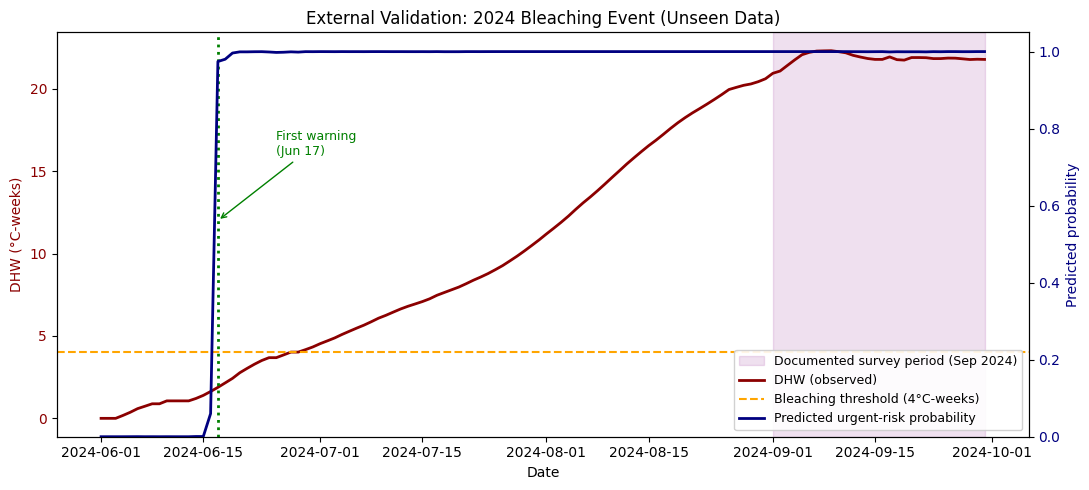

In [ ]:
period_2024 = data_2024[(data_2024['date'] >= '2024-06-01') & (data_2024['date'] <= '2024-09-30')]

fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.axvspan(pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-30'),
            color='purple', alpha=0.12, label='Documented survey period (Sep 2024)')

ax1.plot(period_2024['date'], period_2024['DHW'], color='darkred', linewidth=2, label='DHW (observed)')
ax1.axhline(y=4, color='orange', linestyle='--', linewidth=1.5, label='Bleaching threshold (4°C-weeks)')
ax1.set_xlabel('Date')
ax1.set_ylabel('DHW (°C-weeks)', color='darkred')
ax1.tick_params(axis='y', labelcolor='darkred')

ax2 = ax1.twinx()
ax2.plot(period_2024['date'], period_2024['prob_urgent'], color='navy', linewidth=2, label='Predicted urgent-risk probability')
ax2.set_ylabel('Predicted probability', color='navy')
ax2.tick_params(axis='y', labelcolor='navy')
ax2.set_ylim(0, 1.05)

ax1.axvline(x=pd.Timestamp('2024-06-17'), color='green', linestyle=':', linewidth=2)
ax1.annotate('First warning\n(Jun 17)', xy=(pd.Timestamp('2024-06-17'), 12),
             xytext=(pd.Timestamp('2024-06-25'), 16), fontsize=9, color='green',
             arrowprops=dict(arrowstyle='->', color='green'))

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right', fontsize=9, framealpha=0.9)

plt.title('External Validation: 2024 Bleaching Event (Unseen Data)')
plt.tight_layout()
plt.savefig('figure6_validation_2024.png', dpi=300)
plt.show()

In [ ]:
comparison = pd.DataFrame({
    'Event': ['2020', '2024'],
    'First warning date': ['Aug 11, 2020', 'Jun 17, 2024'],
    'DHW at warning': [1.79, 1.88],
    'Warning probability': [0.953, 0.974],
    'Days before DHW≥4': [10, 10],
    'Peak DHW': [17.42, 22.31],
    'Documented bleaching': ['65% (Oct 2020)', '90% (Sep 2024)']
})
print(comparison.to_string(index=False))

Event First warning date  DHW at warning  Warning probability  Days before DHW≥4  Peak DHW Documented bleaching
 2020       Aug 11, 2020            1.79                0.953                 10     17.42       65% (Oct 2020)
 2024       Jun 17, 2024            1.88                0.974                 10     22.31       90% (Sep 2024)
